# Exploring Dyslexia Patterns Using Machine Learning
CSC1181 — Machine Learning Project

Dataset: Dytective online gamified test, desktop version (Rello et al., 2020, PLOS ONE).
Kaggle DOI: https://doi.org/10.34740/kaggle/dsv/1617514

Pipeline: load -> data-quality repair -> EDA -> statistical tests -> feature engineering
(<=10 features) -> baseline -> models with stratified CV tuning -> test evaluation
-> error / fairness analysis -> feature importance.

Place `Dyt-desktop.csv` next to this notebook and choose Run All. Figures are saved to ./figures and tables to ./results.

## Imports and settings

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, confusion_matrix,
                             RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
SEED = 42
DATA = Path("Dyt-desktop.csv")
FIG, RES = Path("figures"), Path("results")
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
PAL = {"No": "#4C78A8", "Yes": "#E45756"}
TASKS = range(1, 33)

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 1. Load  (the file is semicolon-separated — reading it with commas gives empty columns)

The Kaggle file uses **semicolons** as separators. Reading it as a normal comma CSV (or opening it in Excel) puts everything in one column.

In [2]:
raw = pd.read_csv(DATA, sep=";")
print("Shape:", raw.shape)
print(raw["Dyslexia"].value_counts(), "\n")

Shape: (3644, 197)
Dyslexia
No     3252
Yes     392
Name: count, dtype: int64 



## 2. Data-quality audit and repair

**Why recompute?** Accuracy and Missrate should be proportions between 0 and 1, but some cells lost their leading `0.` (0.875 → 875). In every undamaged cell Accuracy = Hits ÷ Clicks (to 2 d.p.), so recomputing from the raw counts restores the true values exactly, without guessing.

                                   check   value
              Missing values (all cells)    0.00
                          Duplicate rows    0.00
          Accuracy cells > 1 (corrupted) 1841.00
          Missrate cells > 1 (corrupted) 1967.00
    Participants with >=1 corrupted cell 1371.00
         Accuracy cells > 1 after repair    0.00
Share of task attempts with 0 clicks (%)    2.16 



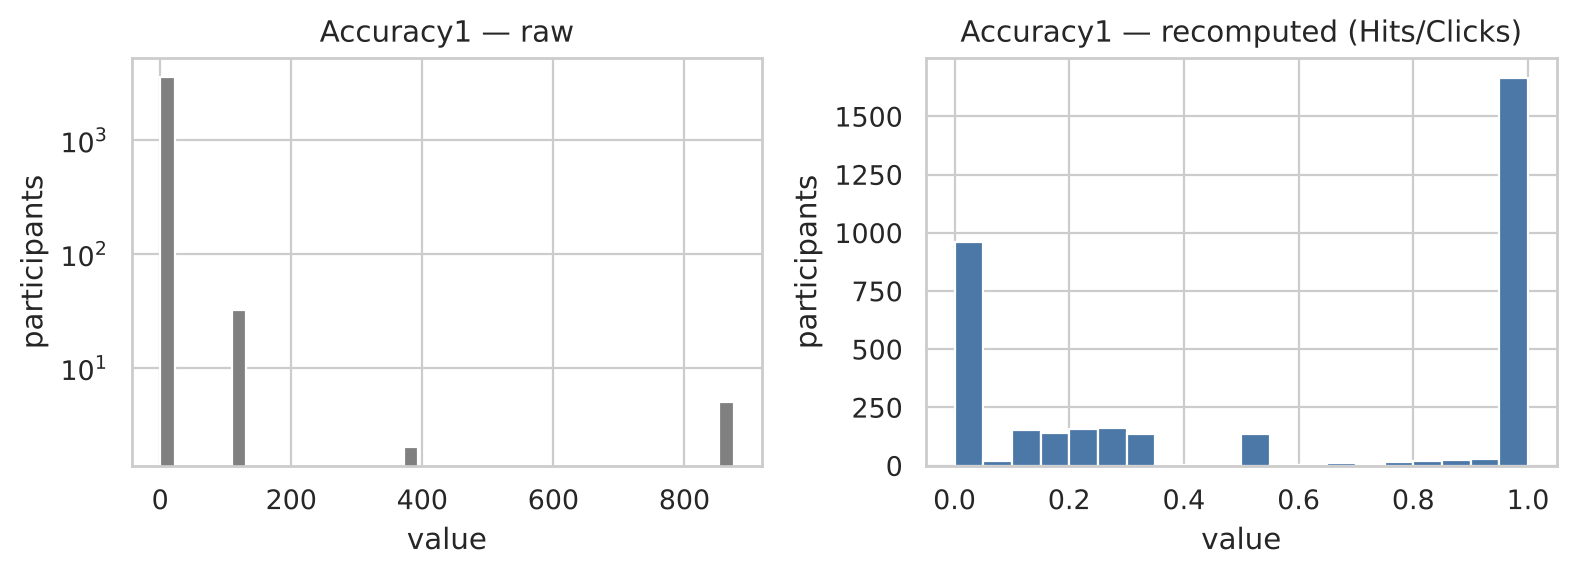

In [3]:
audit = []
acc_cols = [f"Accuracy{i}" for i in TASKS]
miss_cols = [f"Missrate{i}" for i in TASKS]

audit.append(("Missing values (all cells)", int(raw.isna().sum().sum())))
audit.append(("Duplicate rows", int(raw.duplicated().sum())))

# Accuracy / Missrate are proportions (0–1) but some cells lost their leading "0."
# (e.g. 0.875 stored as 875). Accuracy = Hits/Clicks and Missrate = Misses/Clicks in every
# uncorrupted cell (to 2 d.p.), so we recompute both from the raw counts.
n_bad_acc = int((raw[acc_cols] > 1).sum().sum())
n_bad_miss = int((raw[miss_cols] > 1).sum().sum())
rows_bad = int(((raw[acc_cols] > 1) | (raw[miss_cols] > 1)).any(axis=1).sum())
audit += [("Accuracy cells > 1 (corrupted)", n_bad_acc),
          ("Missrate cells > 1 (corrupted)", n_bad_miss),
          ("Participants with >=1 corrupted cell", rows_bad)]

df = raw.copy()
for i in TASKS:
    clicks = df[f"Clicks{i}"].replace(0, np.nan)
    df[f"Accuracy{i}"] = (df[f"Hits{i}"] / clicks).fillna(0)      # no clicks -> 0, as in the source
    df[f"Missrate{i}"] = (df[f"Misses{i}"] / clicks).fillna(0)
audit.append(("Accuracy cells > 1 after repair", int((df[acc_cols] > 1).sum().sum())))

zero_click_share = (df[[f"Clicks{i}" for i in TASKS]] == 0).mean().mean()
audit.append(("Share of task attempts with 0 clicks (%)", round(100 * zero_click_share, 2)))
pd.DataFrame(audit, columns=["check", "value"]).to_csv(RES / "01_data_quality_audit.csv", index=False)
print(pd.DataFrame(audit, columns=["check", "value"]).to_string(index=False), "\n")

# Figure: before/after repair of one task
fig, ax = plt.subplots(1, 2, figsize=(8, 3))
ax[0].hist(raw["Accuracy1"], bins=40, color="grey"); ax[0].set_title("Accuracy1 — raw"); ax[0].set_yscale("log")
ax[1].hist(df["Accuracy1"], bins=20, color="#4C78A8"); ax[1].set_title("Accuracy1 — recomputed (Hits/Clicks)")
for a in ax: a.set_xlabel("value"); a.set_ylabel("participants")
savefig("01_accuracy_repair")

## 3. Encode target and demographics

In [4]:
df["y"] = (df["Dyslexia"] == "Yes").astype(int)
for c in ["Nativelang", "Otherlang"]:
    df[c] = (df[c] == "Yes").astype(int)
df["Gender"] = (df["Gender"] == "Male").astype(int)   # 1 = Male

## 4. Feature engineering (<= 10 features, as the brief requires)

**Feature engineering.** The brief asks for about 10 features or fewer. The 192 per-task columns are summarised into behaviour-level scores, which keeps the model interpretable and avoids overfitting 32 highly correlated tasks.

In [5]:
# 192 per-task columns are summarised into behaviour-level scores; this keeps the model
# interpretable and avoids overfitting 32 highly correlated tasks.
A = df[acc_cols]; C = df[[f"Clicks{i}" for i in TASKS]]; H = df[[f"Hits{i}" for i in TASKS]]
feat = pd.DataFrame({
    "Gender_male": df["Gender"],
    "Native_lang": df["Nativelang"],
    "Other_lang": df["Otherlang"],
    "Age": df["Age"],
    "Mean_accuracy": A.mean(axis=1),           # overall correctness
    "Accuracy_sd": A.std(axis=1),              # consistency across tasks
    "Mean_missrate": df[miss_cols].mean(axis=1),  # overall error rate
    "Total_clicks": C.sum(axis=1),             # activity / speed of interaction
    "Total_hits": H.sum(axis=1),               # amount correctly answered
    "Tasks_zero_hits": (H == 0).sum(axis=1),   # tasks completely failed / skipped
})
y = df["y"]
NUM = ["Age", "Mean_accuracy", "Accuracy_sd", "Mean_missrate", "Total_clicks", "Total_hits", "Tasks_zero_hits"]
CAT = ["Gender_male", "Native_lang", "Other_lang"]
data = feat.assign(Dyslexia=df["Dyslexia"])
data.to_csv(RES / "engineered_dataset.csv", index=False)

## 5. EDA — summary statistics, class balance, distributions, correlations

                  count     mean     std  ...      75%       max  missing_%
Gender_male      3644.0    0.508   0.500  ...    1.000     1.000        0.0
Native_lang      3644.0    0.266   0.442  ...    1.000     1.000        0.0
Other_lang       3644.0    0.811   0.392  ...    1.000     1.000        0.0
Age              3644.0   10.485   2.478  ...   12.000    17.000        0.0
Mean_accuracy    3644.0    0.626   0.109  ...    0.703     0.947        0.0
Accuracy_sd      3644.0    0.386   0.035  ...    0.409     0.499        0.0
Mean_missrate    3644.0    0.215   0.098  ...    0.269     0.693        0.0
Total_clicks     3644.0  245.621  91.994  ...  281.000  1685.000        0.0
Total_hits       3644.0  112.028  39.665  ...  139.000   293.000        0.0
Tasks_zero_hits  3644.0    3.915   3.179  ...    5.000    29.000        0.0

[10 rows x 9 columns] 



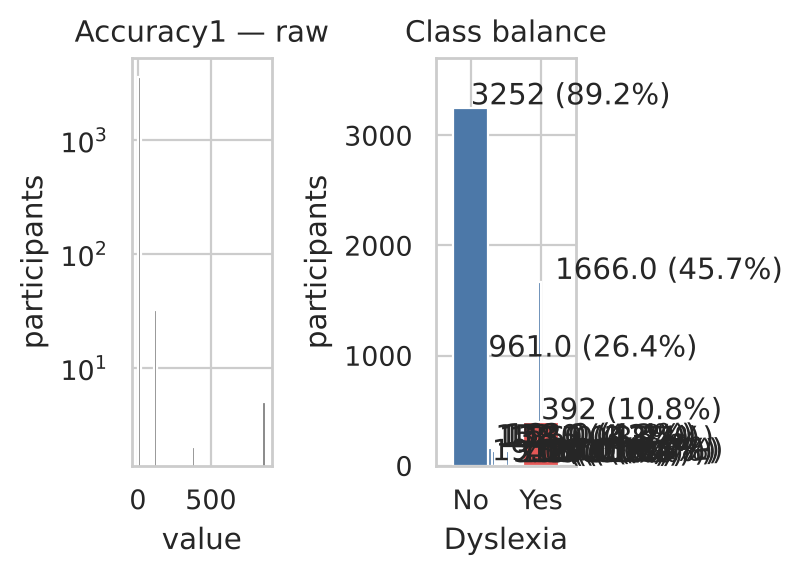

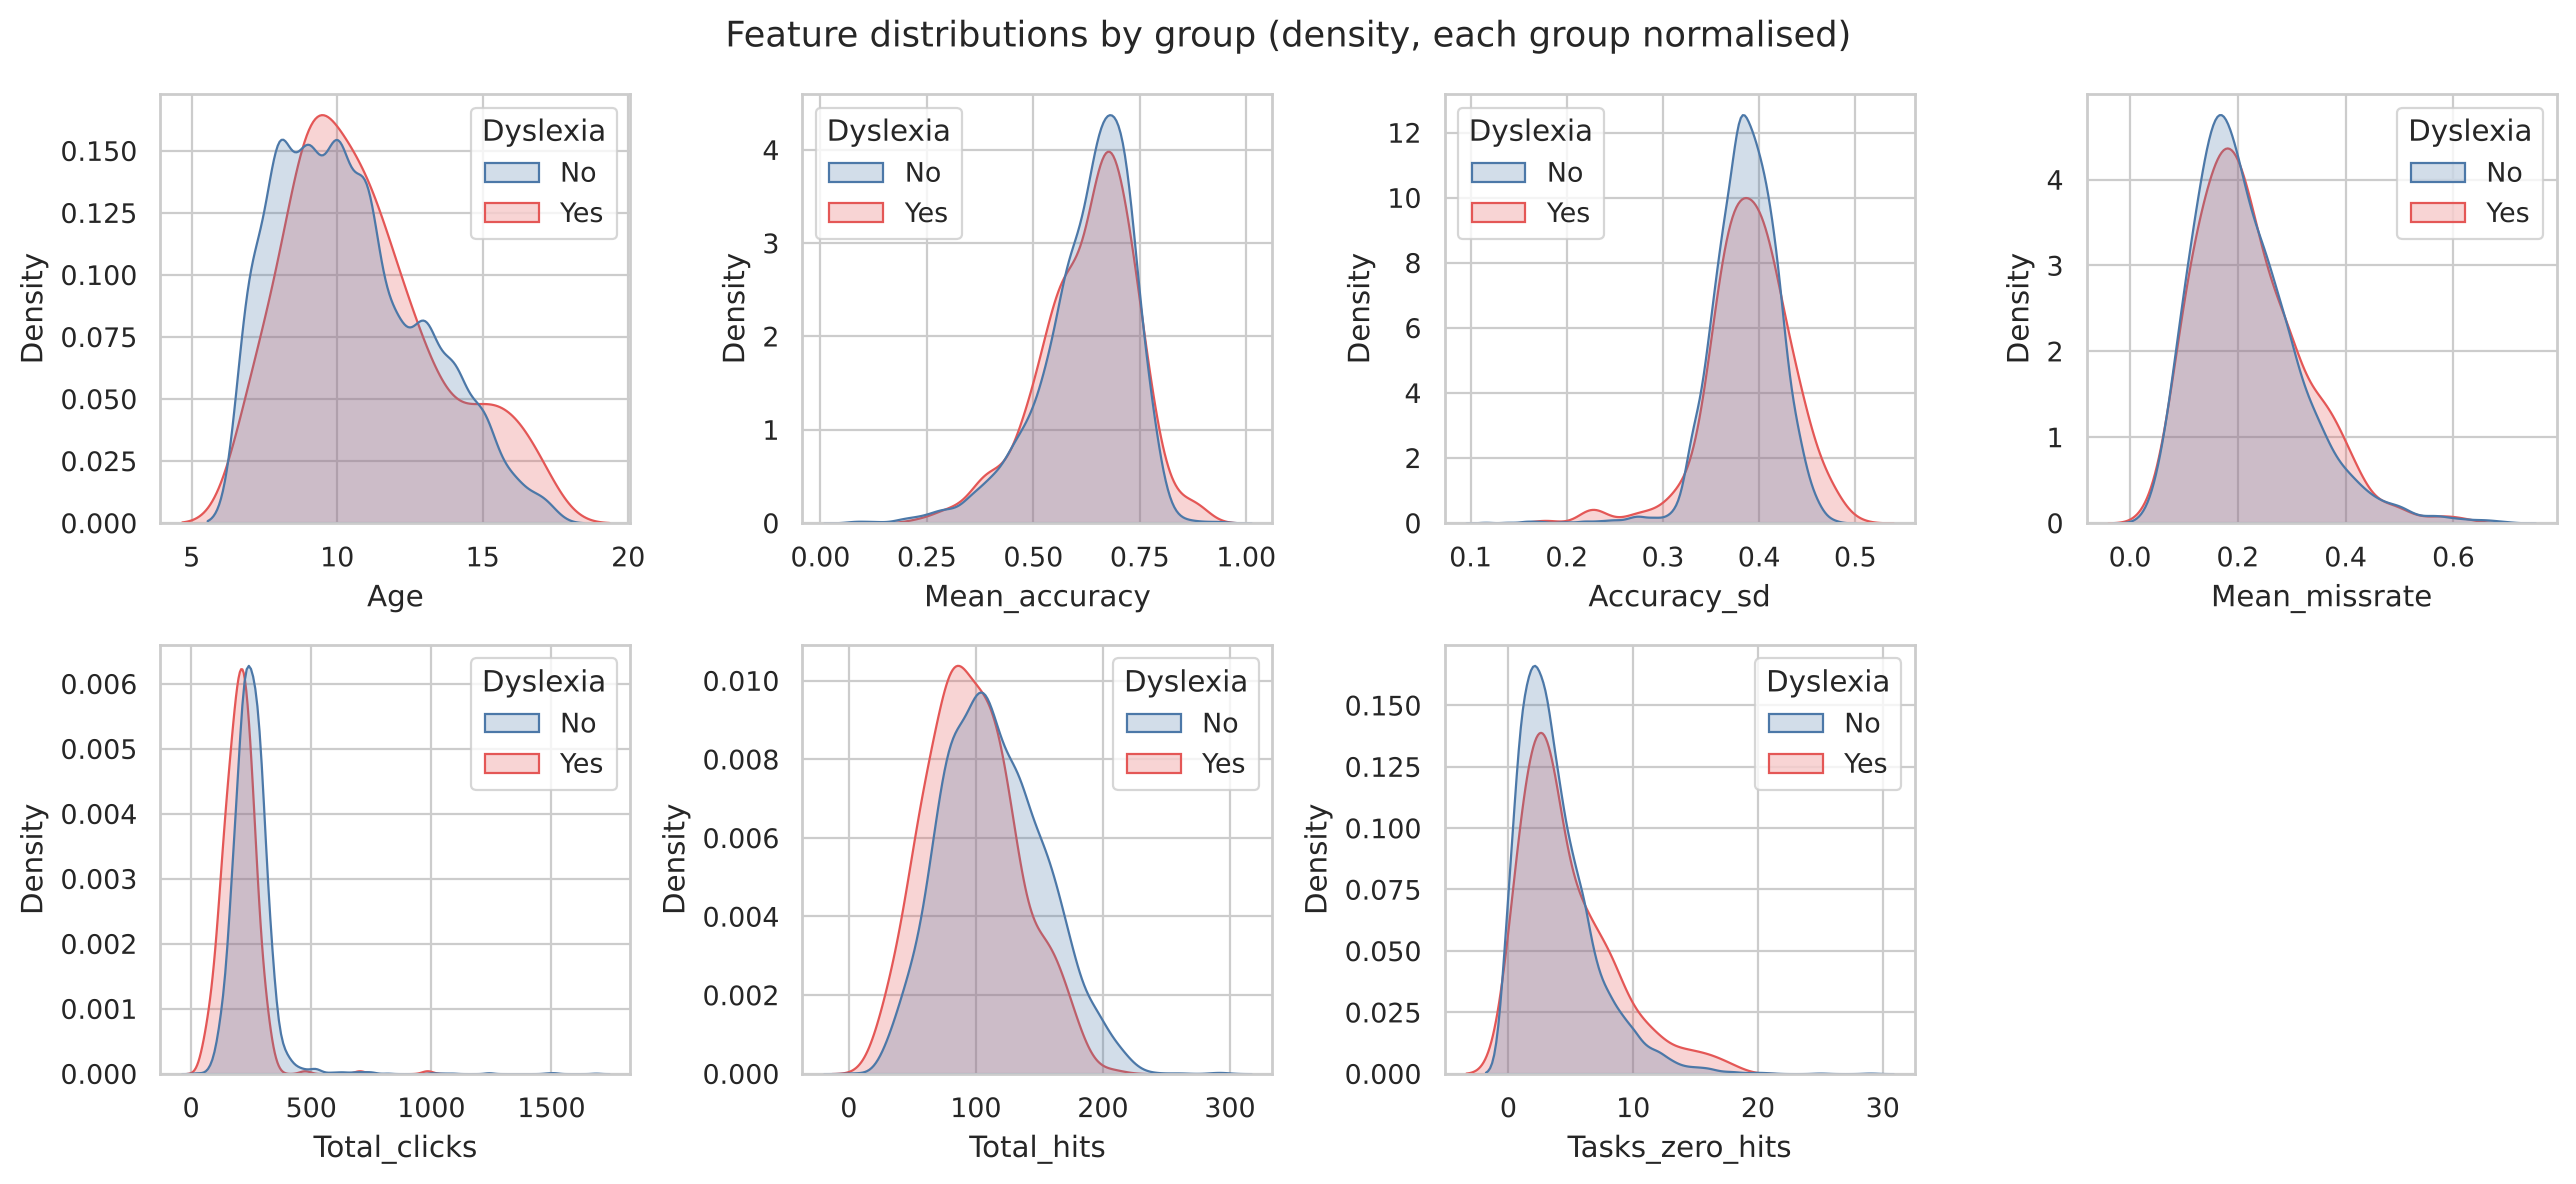

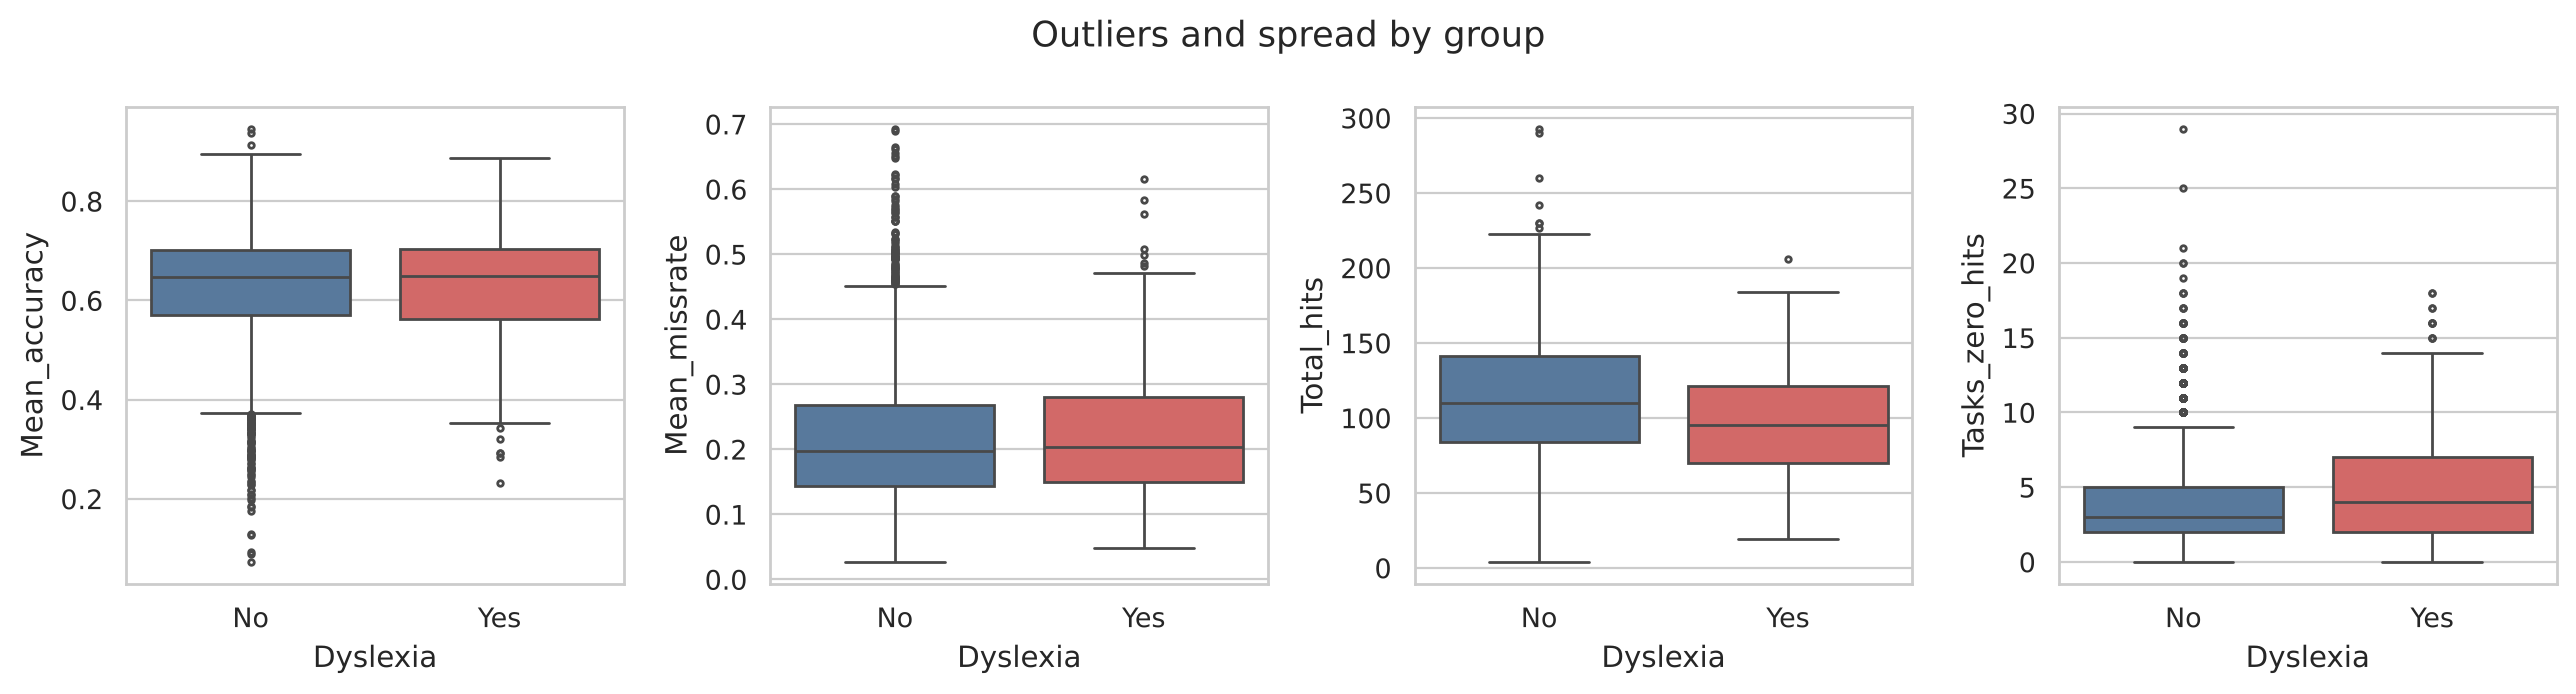

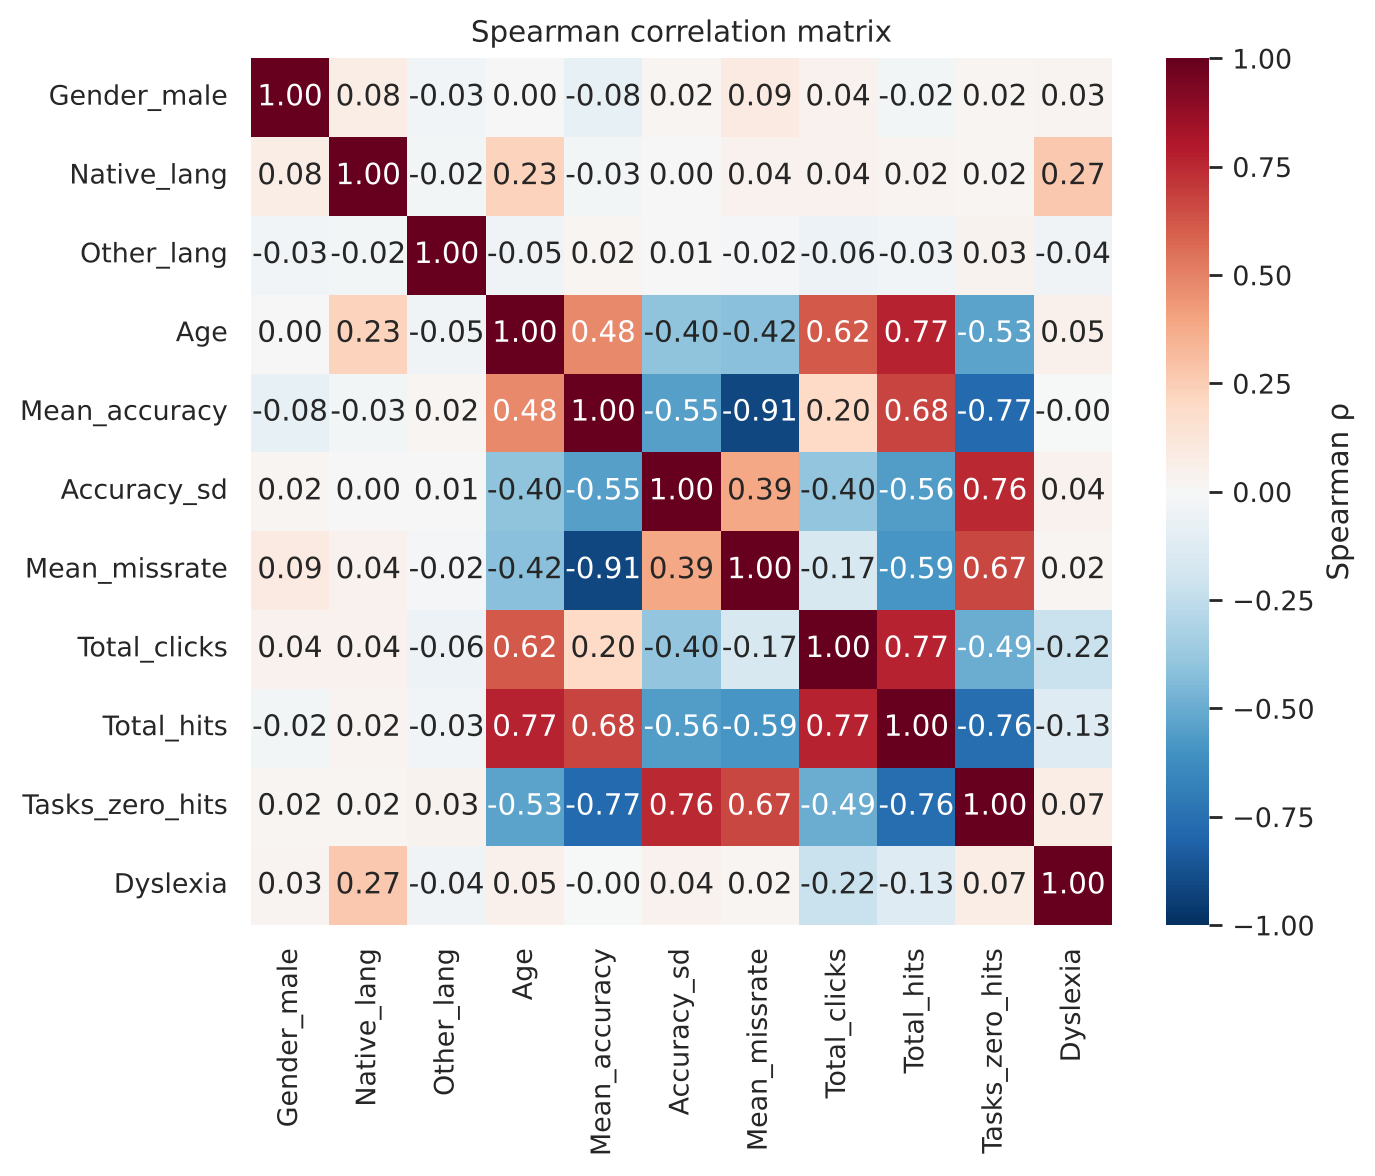

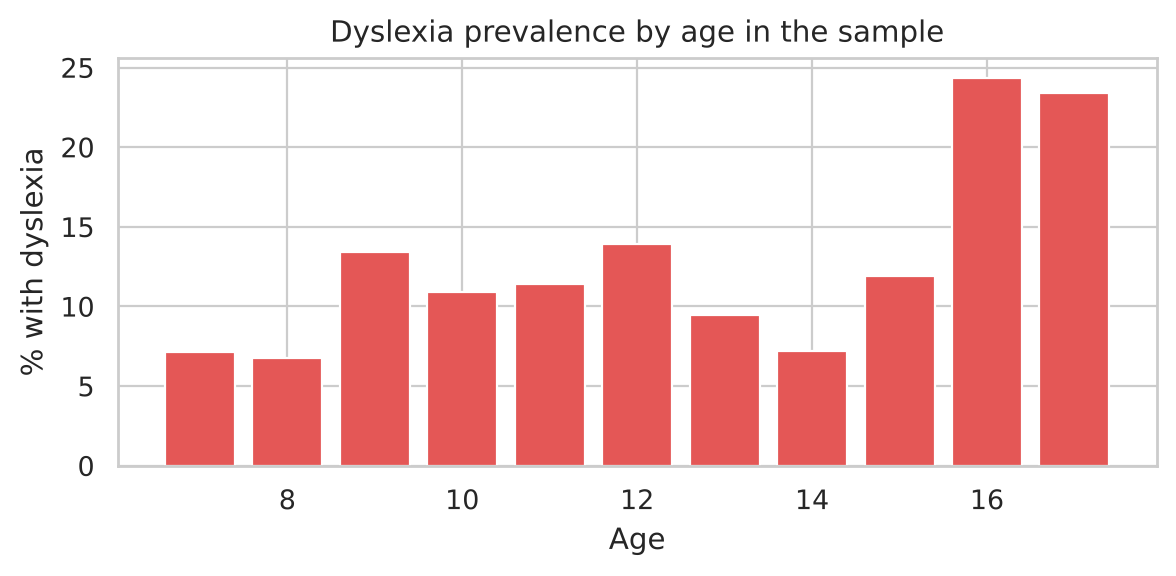

In [6]:
summary = feat.describe().T.round(3)
summary["missing_%"] = 100 * feat.isna().mean()
summary.to_csv(RES / "02_summary_statistics.csv")
print(summary, "\n")

ax = df["Dyslexia"].value_counts().plot.bar(color=[PAL["No"], PAL["Yes"]], figsize=(4, 3), rot=0)
for p in ax.patches:
    ax.annotate(f"{p.get_height()} ({100*p.get_height()/len(df):.1f}%)", (p.get_x() + .25, p.get_height() + 30))
ax.set_title("Class balance"); ax.set_ylabel("participants"); ax.set_ylim(0, 3700)
savefig("02_class_balance")

fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for ax, col in zip(axes.flat, NUM):
    sns.kdeplot(data=data, x=col, hue="Dyslexia", common_norm=False, fill=True, palette=PAL, ax=ax, warn_singular=False)
axes.flat[-1].axis("off")
fig.suptitle("Feature distributions by group (density, each group normalised)")
savefig("03_distributions")

fig, axes = plt.subplots(1, 4, figsize=(13, 3.5))
for ax, col in zip(axes, ["Mean_accuracy", "Mean_missrate", "Total_hits", "Tasks_zero_hits"]):
    sns.boxplot(data=data, x="Dyslexia", y=col, palette=PAL, ax=ax, fliersize=2)
fig.suptitle("Outliers and spread by group")
savefig("04_boxplots")

plt.figure(figsize=(7, 6))
sns.heatmap(feat.assign(Dyslexia=y).corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, cbar_kws={"label": "Spearman ρ"})
plt.title("Spearman correlation matrix")
savefig("05_correlation_heatmap")

# Dyslexia rate by age (pattern exploration)
rate = df.groupby("Age")["y"].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(rate.index, 100 * rate["mean"], color=PAL["Yes"])
ax.set_xlabel("Age"); ax.set_ylabel("% with dyslexia"); ax.set_title("Dyslexia prevalence by age in the sample")
savefig("06_prevalence_by_age")

## 6. Statistical tests (group differences)

**Choice of tests.** The Shapiro–Wilk p-values show the features are not normally distributed, so the non-parametric Mann–Whitney U test is used. Bonferroni correction controls false positives across 10 tests. Effect sizes show how big each difference is, not only whether it is significant.

In [7]:
# Numeric: Mann–Whitney U (non-normal distributions — see Shapiro p-values) + rank-biserial effect size.
# Categorical: chi-square test of independence + Cramér's V. Bonferroni correction for 10 tests.
rows = []
for col in NUM:
    a, b = feat.loc[y == 1, col], feat.loc[y == 0, col]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    r_rb = 1 - 2 * u / (len(a) * len(b))
    sh_p = stats.shapiro(feat[col].sample(500, random_state=SEED)).pvalue
    rows.append([col, "Mann-Whitney U", a.median(), b.median(), u, p, -r_rb, "rank-biserial r", sh_p])
for col in CAT:
    tab = pd.crosstab(feat[col], y)
    chi2, p, dof, _ = stats.chi2_contingency(tab)
    v = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
    rows.append([col, "Chi-square", feat.loc[y == 1, col].mean(), feat.loc[y == 0, col].mean(), chi2, p, v, "Cramér's V", np.nan])
tests = pd.DataFrame(rows, columns=["feature", "test", "dyslexia_median_or_rate", "control_median_or_rate",
                                    "statistic", "p_value", "effect_size", "effect_measure", "shapiro_p"])
tests["p_bonferroni"] = np.minimum(tests["p_value"] * len(tests), 1)
tests["significant_0.05"] = tests["p_bonferroni"] < 0.05
tests = tests.round(4)
tests.to_csv(RES / "03_statistical_tests.csv", index=False)
print(tests[["feature", "test", "p_bonferroni", "effect_size", "effect_measure"]].to_string(index=False), "\n")

        feature           test  p_bonferroni  effect_size  effect_measure
            Age Mann-Whitney U        0.0103       0.1006 rank-biserial r
  Mean_accuracy Mann-Whitney U        1.0000      -0.0004 rank-biserial r
    Accuracy_sd Mann-Whitney U        0.1629       0.0742 rank-biserial r
  Mean_missrate Mann-Whitney U        1.0000       0.0417 rank-biserial r
   Total_clicks Mann-Whitney U        0.0000      -0.4108 rank-biserial r
     Total_hits Mann-Whitney U        0.0000      -0.2390 rank-biserial r
Tasks_zero_hits Mann-Whitney U        0.0002       0.1323 rank-biserial r
    Gender_male     Chi-square        1.0000       0.0272      Cramér's V
    Native_lang     Chi-square        0.0000       0.2708      Cramér's V
     Other_lang     Chi-square        0.1763       0.0393      Cramér's V 



## 7. Train/test split (stratified 80/20) — test set is untouched until final evaluation

The test set (20%) is held back until the final evaluation. Stratification keeps the 10.8% dyslexia rate the same in both sets.

In [8]:
X_tr, X_te, y_tr, y_te = train_test_split(feat, y, test_size=0.2, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(f"Train {X_tr.shape}, Test {X_te.shape}, positives train {y_tr.mean():.3f}, test {y_te.mean():.3f}\n")

Train (2915, 10), Test (729, 10), positives train 0.108, test 0.107



## 8. Baselines and models

**Baselines** show what you get with no learning at all. The majority-class baseline scores high accuracy but detects nobody, which is why recall, balanced accuracy and ROC AUC are the main metrics. Class imbalance is handled with `class_weight='balanced'` rather than oversampling, so no synthetic records are created.

In [9]:
# Class imbalance (~11% positive) is handled with class_weight='balanced' rather than
# oversampling, so no synthetic records are created and CV folds stay leak-free.
models = {
    "Baseline: majority class": (DummyClassifier(strategy="most_frequent"), {}),
    "Baseline: stratified random": (DummyClassifier(strategy="stratified", random_state=SEED), {}),
    "Logistic Regression": (Pipeline([("sc", StandardScaler()),
                                      ("clf", LogisticRegression(class_weight="balanced", max_iter=2000))]),
                            {"clf__C": [0.01, 0.1, 1, 10]}),
    "Random Forest": (RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1),
                      {"n_estimators": [300], "max_depth": [4, 8, None], "min_samples_leaf": [1, 5, 20]}),
    "Gradient Boosting": (HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
                          {"learning_rate": [0.03, 0.1], "max_depth": [3, None], "max_iter": [200]}),
    "SVM (RBF)": (Pipeline([("sc", StandardScaler()),
                            ("clf", SVC(class_weight="balanced", probability=True, random_state=SEED))]),
                  {"clf__C": [0.1, 1, 10], "clf__gamma": ["scale", 0.1]}),
}

def scores(y_true, y_pred, y_prob):
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Balanced acc.": balanced_accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred),
            "F1": f1_score(y_true, y_pred),
            "ROC AUC": roc_auc_score(y_true, y_prob),
            "PR AUC": average_precision_score(y_true, y_prob)}

fitted, cv_rows, test_rows = {}, [], []
for name, (est, grid) in models.items():
    gs = GridSearchCV(est, grid or {}, scoring="roc_auc", cv=cv, n_jobs=-1, refit=True) if grid else est
    gs.fit(X_tr, y_tr)
    best = gs.best_estimator_ if grid else gs
    fitted[name] = best
    # cross-validated performance on the training set (honest estimate for model choice)
    oof = cross_val_predict(best, X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]
    oof_lab = cross_val_predict(best, X_tr, y_tr, cv=cv, method="predict")
    cv_rows.append({"Model": name, **scores(y_tr, oof_lab, oof),
                    "Best params": gs.best_params_ if grid else "-"})
    prob = best.predict_proba(X_te)[:, 1]
    test_rows.append({"Model": name, **scores(y_te, best.predict(X_te), prob)})

cv_res = pd.DataFrame(cv_rows).round(3); test_res = pd.DataFrame(test_rows).round(3)
cv_res.to_csv(RES / "04_cv_results_train.csv", index=False)
test_res.to_csv(RES / "05_test_results.csv", index=False)
print("5-fold CV (train):\n", cv_res.drop(columns="Best params").to_string(index=False), "\n")
print("Held-out test:\n", test_res.to_string(index=False), "\n")

# Model selection uses CV results only (never the test set). Models whose CV ROC AUC is
# within 0.01 of the best are treated as equivalent; among those we prefer the most
# interpretable (order below), because a screening tool must be explainable.
ml_only = cv_res[~cv_res.Model.str.startswith("Baseline")]
contenders = ml_only[ml_only["ROC AUC"] >= ml_only["ROC AUC"].max() - 0.01]["Model"].tolist()
preference = ["Logistic Regression", "Random Forest", "Gradient Boosting", "SVM (RBF)"]
best_name = next(m for m in preference if m in contenders)
best = fitted[best_name]
print("Equivalent on CV ROC AUC:", contenders, "-> selected:", best_name, "\n")

5-fold CV (train):
                       Model  Accuracy  Balanced acc.  Precision  Recall    F1  ROC AUC  PR AUC
   Baseline: majority class     0.892          0.500      0.000   0.000 0.000    0.500   0.108
Baseline: stratified random     0.791          0.501      0.109   0.131 0.119    0.501   0.108
        Logistic Regression     0.764          0.755      0.278   0.742 0.404    0.829   0.402
              Random Forest     0.773          0.758      0.286   0.739 0.412    0.825   0.382
          Gradient Boosting     0.789          0.759      0.301   0.720 0.424    0.832   0.406
                  SVM (RBF)     0.778          0.757      0.290   0.729 0.415    0.834   0.385 

Held-out test:
                       Model  Accuracy  Balanced acc.  Precision  Recall    F1  ROC AUC  PR AUC
   Baseline: majority class     0.893          0.500      0.000   0.000 0.000    0.500   0.107
Baseline: stratified random     0.793          0.483      0.080   0.090 0.085    0.483   0.105
        Logi

## 9. Evaluation figures — metric comparison, ROC, PR, confusion matrix

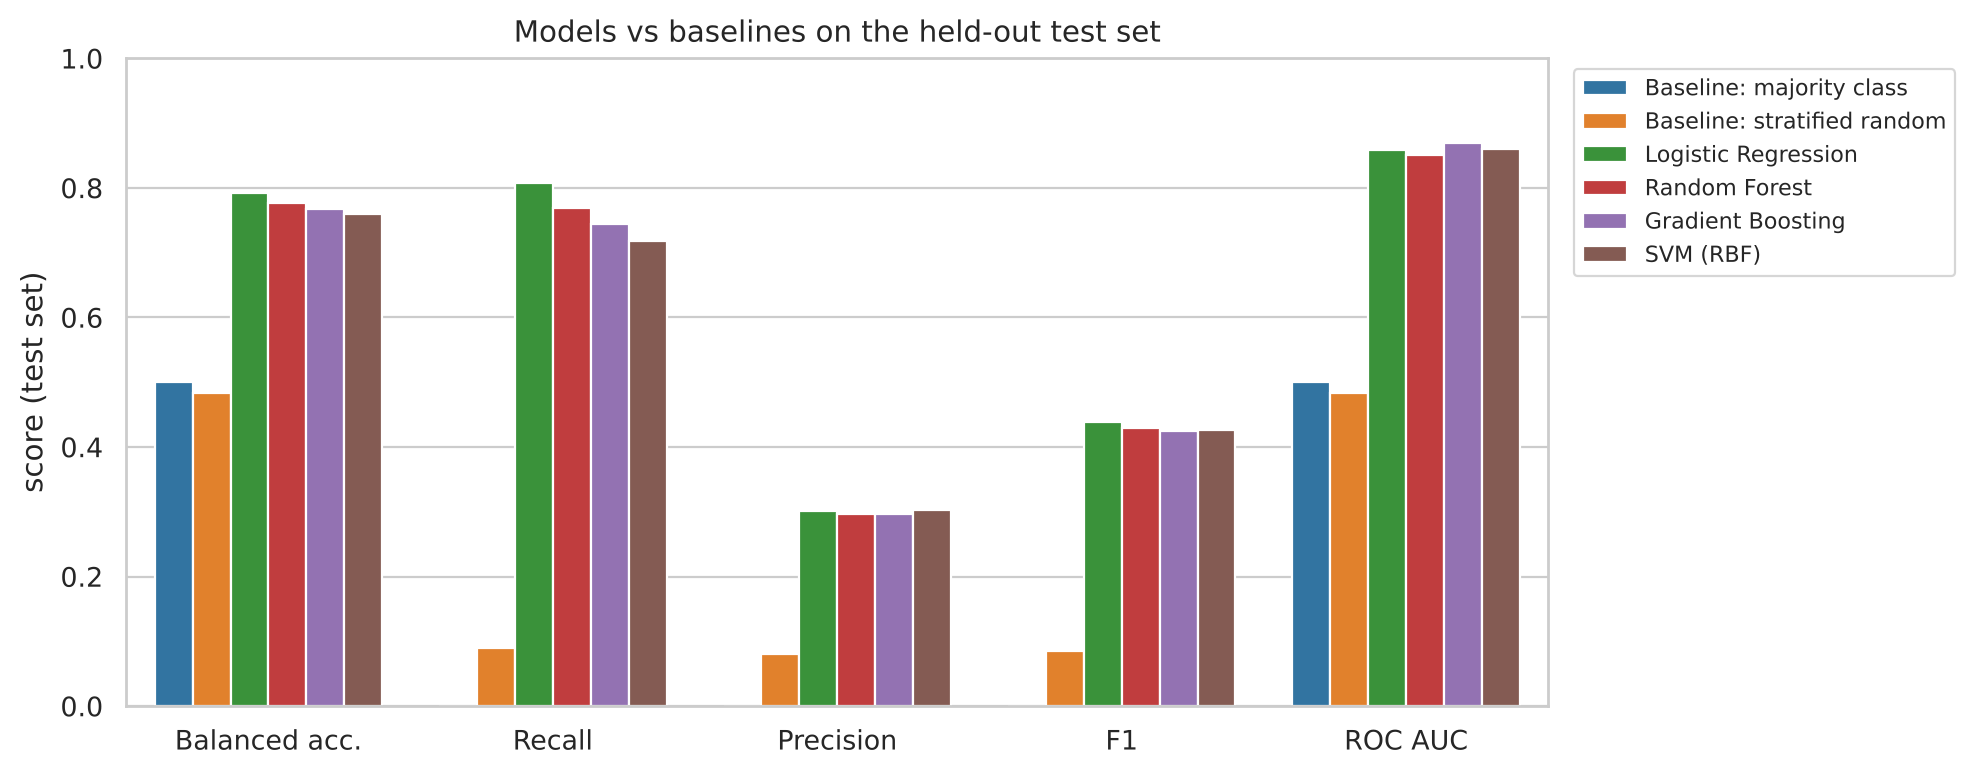

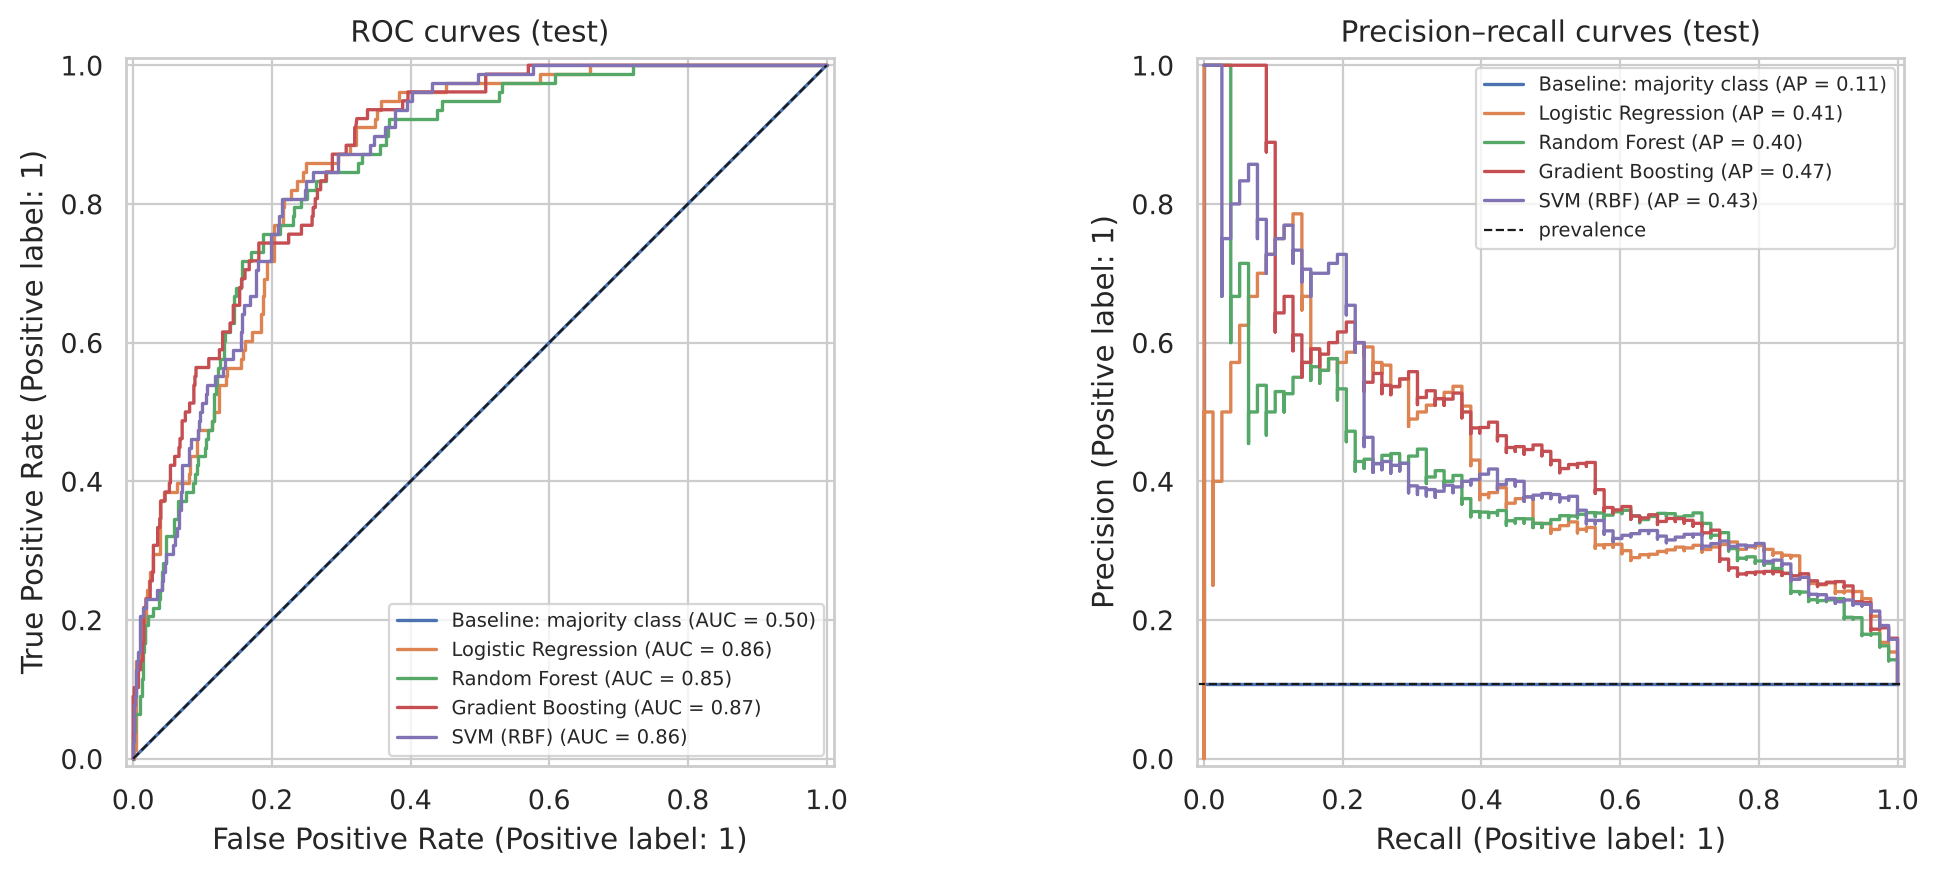

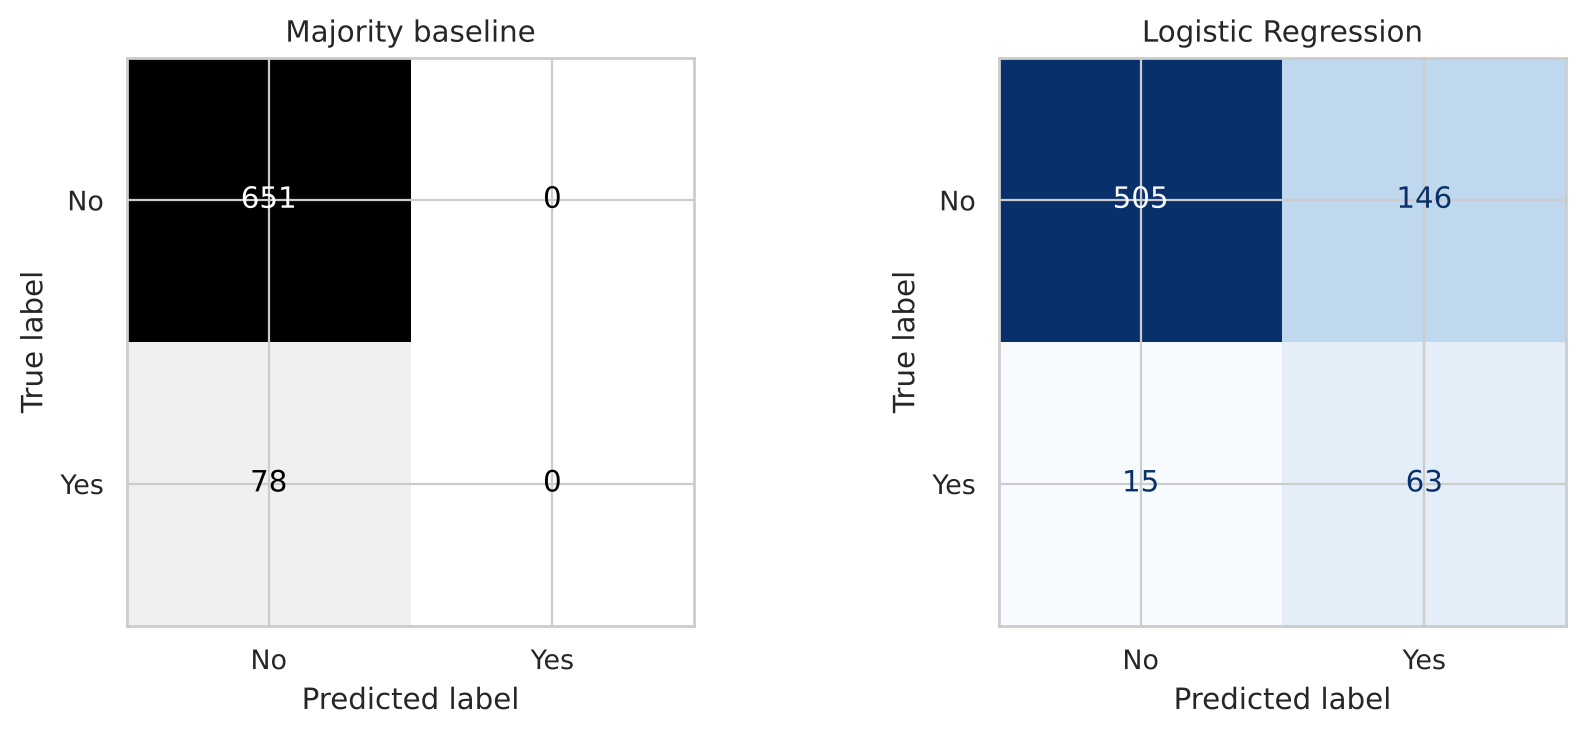

In [10]:
plot_df = test_res.melt(id_vars="Model", value_vars=["Balanced acc.", "Recall", "Precision", "F1", "ROC AUC"])
plt.figure(figsize=(10, 4))
sns.barplot(data=plot_df, x="variable", y="value", hue="Model", palette="tab10")
plt.ylim(0, 1); plt.xlabel(""); plt.ylabel("score (test set)")
plt.title("Models vs baselines on the held-out test set")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
savefig("07_model_comparison")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for name, m in fitted.items():
    if name.startswith("Baseline: strat"): continue
    RocCurveDisplay.from_estimator(m, X_te, y_te, ax=ax[0], name=name)
    PrecisionRecallDisplay.from_estimator(m, X_te, y_te, ax=ax[1], name=name)
ax[0].plot([0, 1], [0, 1], "k--", lw=.8); ax[0].set_title("ROC curves (test)")
ax[1].axhline(y_te.mean(), color="k", ls="--", lw=.8, label="prevalence"); ax[1].set_title("Precision–recall curves (test)")
for a in ax: a.legend(fontsize=7)
savefig("08_roc_pr_curves")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
ConfusionMatrixDisplay.from_estimator(fitted["Baseline: majority class"], X_te, y_te, display_labels=["No", "Yes"],
                                      cmap="Greys", ax=ax[0], colorbar=False)
ax[0].set_title("Majority baseline")
ConfusionMatrixDisplay.from_estimator(best, X_te, y_te, display_labels=["No", "Yes"], cmap="Blues", ax=ax[1], colorbar=False)
ax[1].set_title(best_name)
savefig("09_confusion_matrices")

## 10. Bootstrap 95% confidence intervals for the selected model (test set)

Bootstrap resampling of the test set gives 95% confidence intervals, showing how much the scores could vary with a different sample.

In [11]:
rng = np.random.default_rng(SEED)
p_best = best.predict_proba(X_te)[:, 1]; yhat = best.predict(X_te); yt = y_te.to_numpy()
boot = []
for _ in range(1000):
    idx = rng.integers(0, len(yt), len(yt))
    if yt[idx].sum() == 0: continue
    boot.append([recall_score(yt[idx], yhat[idx]), precision_score(yt[idx], yhat[idx], zero_division=0),
                 f1_score(yt[idx], yhat[idx]), roc_auc_score(yt[idx], p_best[idx])])
ci = pd.DataFrame(np.percentile(boot, [2.5, 50, 97.5], axis=0).T, index=["Recall", "Precision", "F1", "ROC AUC"],
                  columns=["2.5%", "median", "97.5%"]).round(3)
ci.to_csv(RES / "06_bootstrap_ci_best_model.csv")
print("Bootstrap 95% CI:\n", ci, "\n")

Bootstrap 95% CI:
             2.5%  median  97.5%
Recall     0.714   0.809  0.893
Precision  0.239   0.300  0.366
F1         0.362   0.438  0.510
ROC AUC    0.819   0.859  0.892 



## 11. Threshold analysis — screening tools favour recall

A screening tool usually cares more about missing as few dyslexic children as possible (recall) than about false alarms. This plot shows the trade-off as the decision threshold changes.

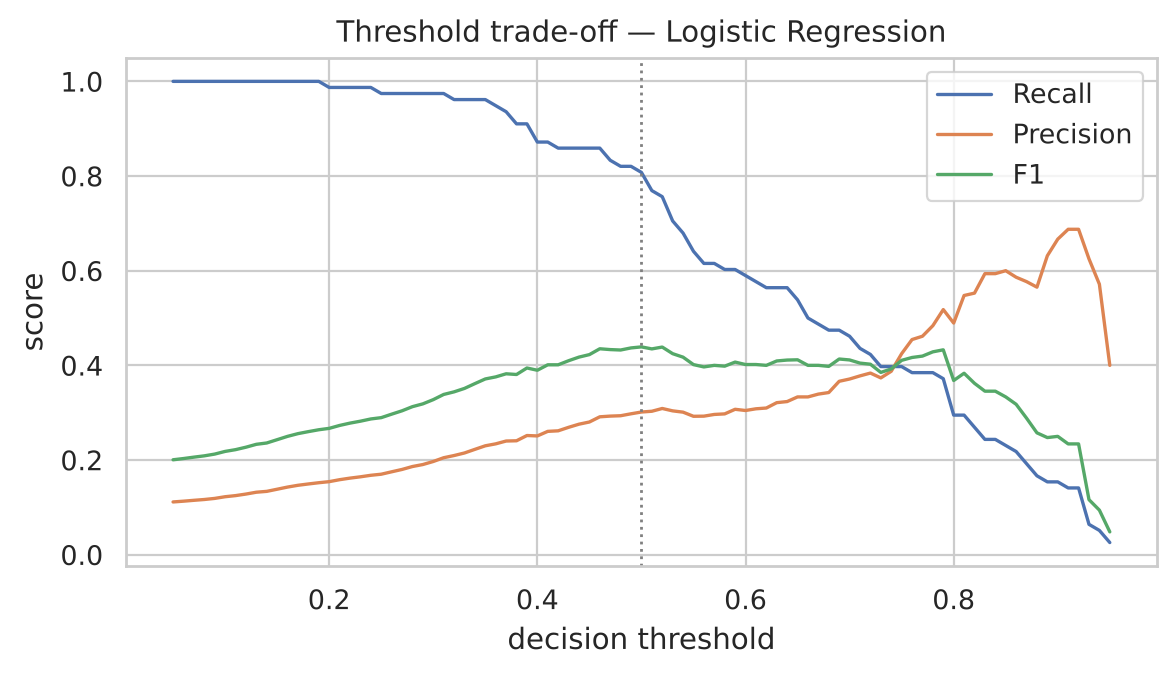

In [12]:
thr = np.linspace(0.05, 0.95, 91)
tr = pd.DataFrame({"threshold": thr,
                   "Recall": [recall_score(yt, p_best >= t) for t in thr],
                   "Precision": [precision_score(yt, p_best >= t, zero_division=0) for t in thr],
                   "F1": [f1_score(yt, p_best >= t) for t in thr]})
plt.figure(figsize=(6, 3.5))
for c in ["Recall", "Precision", "F1"]: plt.plot(tr.threshold, tr[c], label=c)
plt.axvline(0.5, color="grey", ls=":", lw=1)
plt.xlabel("decision threshold"); plt.ylabel("score"); plt.title(f"Threshold trade-off — {best_name}")
plt.legend(); savefig("10_threshold_tradeoff")
tr.round(3).to_csv(RES / "07_threshold_analysis.csv", index=False)

## 12. Error analysis and fairness — where does the model fail?

**Error and fairness analysis.** Compare recall and false-positive rate across age bands, gender and native language to check whether the model works equally well for everyone.

Subgroup performance:
           subgroup   n  positives  Recall   FPR  Balanced acc.
      Age_band=7–9 293         33   0.727 0.173          0.777
    Age_band=10–12 275         25   0.880 0.228          0.826
    Age_band=13–17 161         20   0.850 0.312          0.769
Gender_male=Female 361         40   0.875 0.202          0.836
  Gender_male=Male 368         38   0.737 0.245          0.746
    Native_lang=No 541         30   0.600 0.068          0.766
   Native_lang=Yes 188         48   0.938 0.793          0.572 

Mean feature values by outcome:
             Age  Mean_accuracy  Accuracy_sd  ...  Total_hits  Tasks_zero_hits   prob
outcome                                      ...                                    
FN        9.800          0.578        0.408  ...      93.867            6.000  0.382
FP       11.144          0.626        0.389  ...     102.096            4.240  0.680
TN       10.202          0.622        0.381  ...     118.549            3.602  0.231
TP       11.0

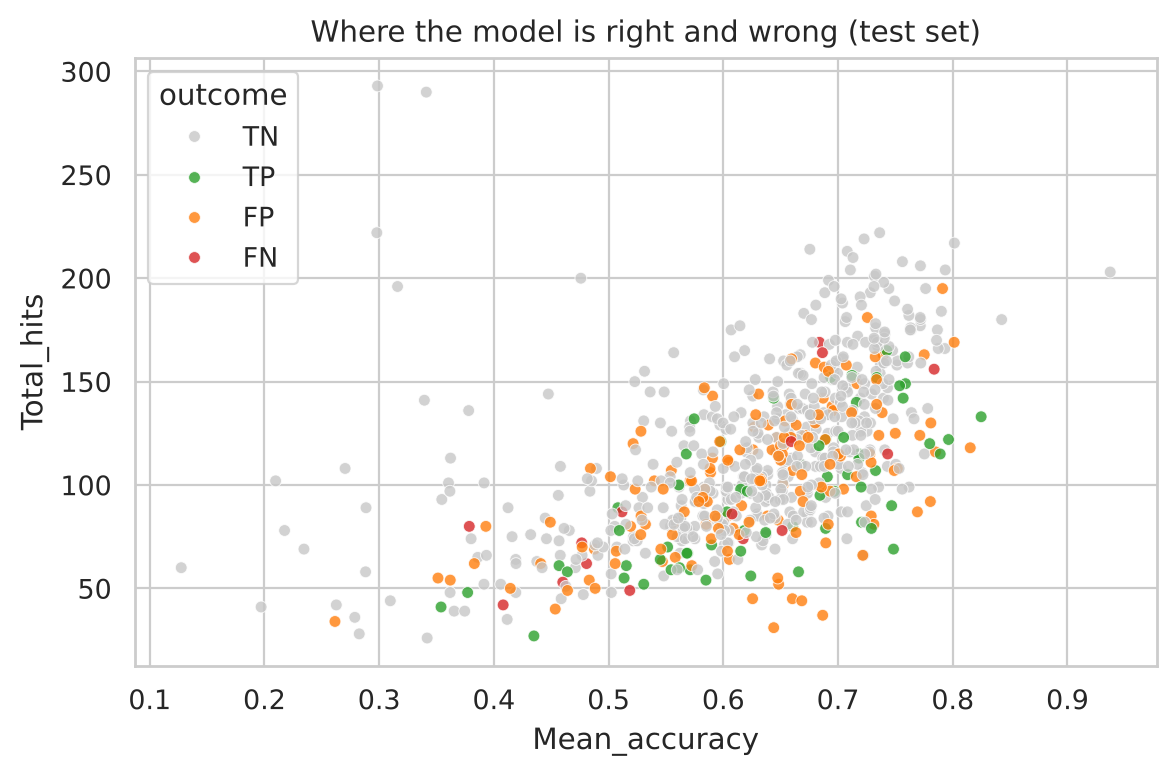

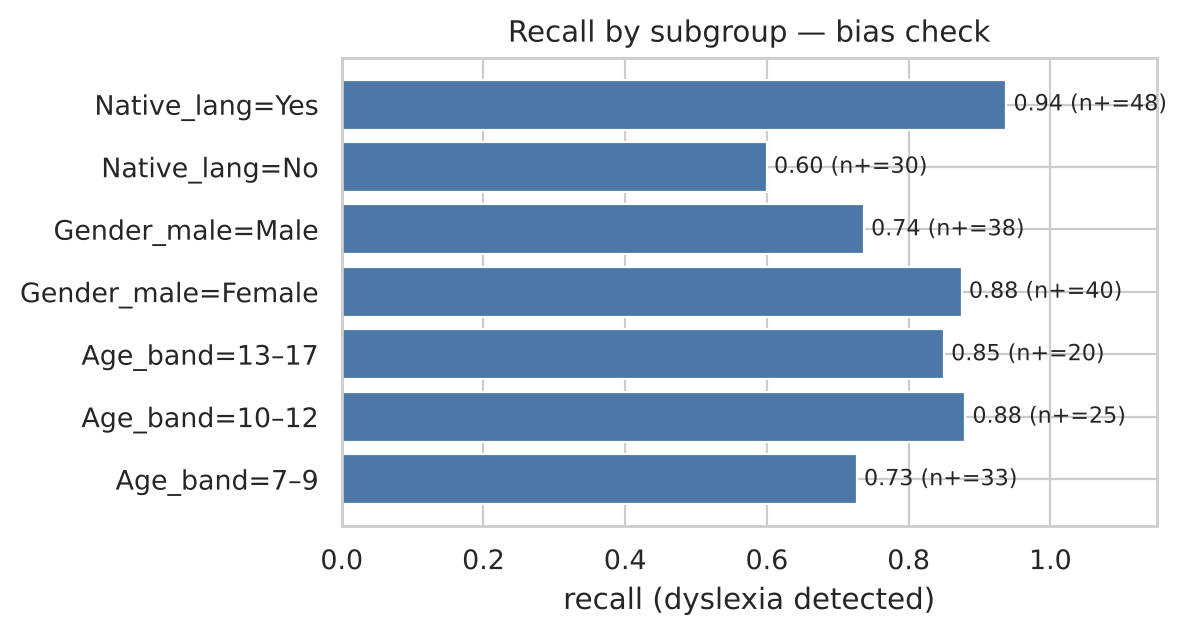

In [13]:
te = X_te.copy(); te["y"] = yt; te["pred"] = yhat; te["prob"] = p_best
te["outcome"] = np.select([(te.y == 1) & (te.pred == 1), (te.y == 1) & (te.pred == 0),
                           (te.y == 0) & (te.pred == 1)], ["TP", "FN", "FP"], "TN")
te["Age_band"] = pd.cut(te["Age"], [6, 9, 12, 17], labels=["7–9", "10–12", "13–17"])

def subgroup(col, labels=None):
    out = []
    for g, d in te.groupby(col, observed=True):
        out.append({"subgroup": f"{col}={labels.get(g, g) if labels else g}", "n": len(d), "positives": int(d.y.sum()),
                    "Recall": recall_score(d.y, d.pred) if d.y.sum() else np.nan,
                    "FPR": ((d.pred == 1) & (d.y == 0)).sum() / max((d.y == 0).sum(), 1),
                    "Balanced acc.": balanced_accuracy_score(d.y, d.pred) if d.y.nunique() > 1 else np.nan})
    return out
fair = pd.DataFrame(subgroup("Age_band") + subgroup("Gender_male", {0: "Female", 1: "Male"}) +
                    subgroup("Native_lang", {0: "No", 1: "Yes"})).round(3)
fair.to_csv(RES / "08_subgroup_performance.csv", index=False)
print("Subgroup performance:\n", fair.to_string(index=False), "\n")

err_profile = te.groupby("outcome")[NUM + ["prob"]].mean().round(3)
err_profile.to_csv(RES / "09_error_profile.csv")
print("Mean feature values by outcome:\n", err_profile, "\n")

plt.figure(figsize=(6, 4))
sns.scatterplot(data=te, x="Mean_accuracy", y="Total_hits", hue="outcome",
                palette={"TN": "#c7c7c7", "TP": "#2ca02c", "FN": "#d62728", "FP": "#ff7f0e"}, s=18, alpha=.8)
plt.title("Where the model is right and wrong (test set)")
savefig("11_error_scatter")

fig, ax = plt.subplots(figsize=(6, 3.3))
f2 = fair.dropna(subset=["Recall"])
ax.barh(f2.subgroup, f2.Recall, color="#4C78A8")
for i, (r, n) in enumerate(zip(f2.Recall, f2.positives)): ax.text(r + .01, i, f"{r:.2f} (n+={n})", va="center", fontsize=8)
ax.set_xlim(0, 1.15); ax.set_xlabel("recall (dyslexia detected)"); ax.set_title("Recall by subgroup — bias check")
savefig("12_subgroup_recall")

## 13. Feature importance (permutation importance on the test set, metric = ROC AUC)

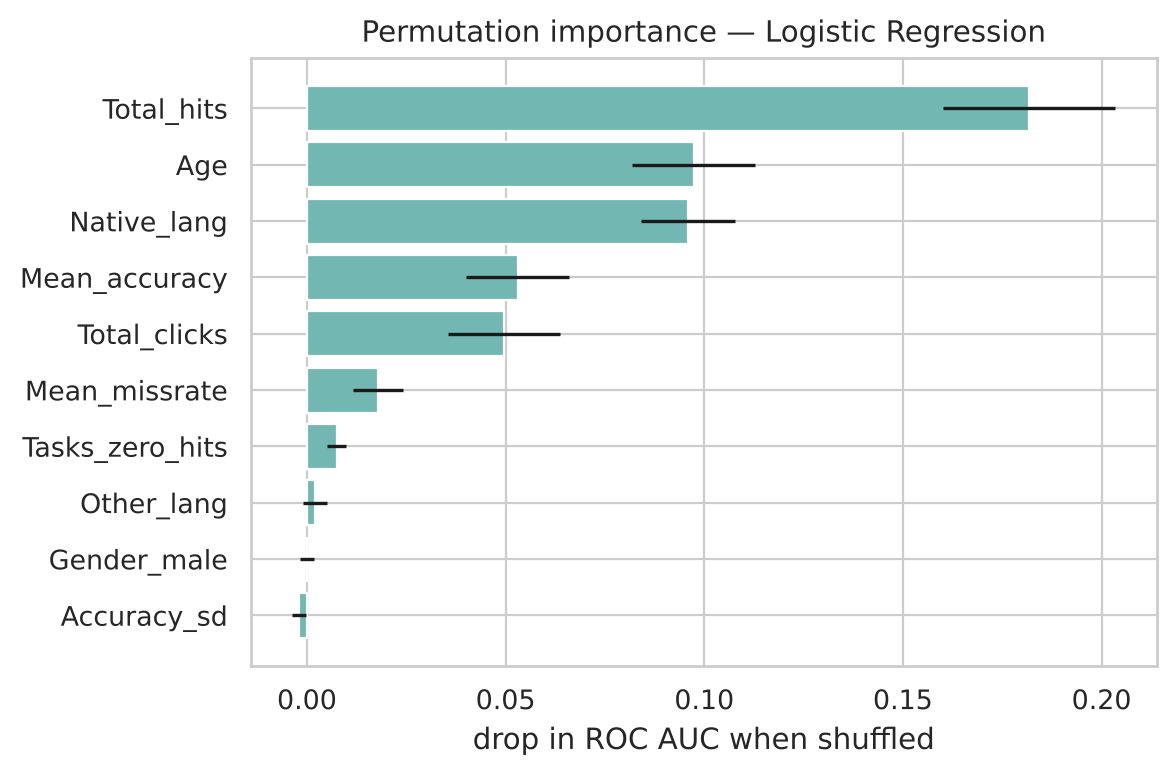

In [14]:
pi = permutation_importance(best, X_te, y_te, scoring="roc_auc", n_repeats=30, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"feature": X_te.columns, "importance": pi.importances_mean, "sd": pi.importances_std})
imp = imp.sort_values("importance", ascending=True)
imp.round(4).to_csv(RES / "10_permutation_importance.csv", index=False)
plt.figure(figsize=(6, 4))
plt.barh(imp.feature, imp.importance, xerr=imp.sd, color="#72B7B2")
plt.xlabel("drop in ROC AUC when shuffled"); plt.title(f"Permutation importance — {best_name}")
savefig("13_permutation_importance")

if "Logistic Regression" in fitted:   # interpretable coefficients
    lr = fitted["Logistic Regression"]
    coef = pd.DataFrame({"feature": X_tr.columns, "coef_std": lr.named_steps["clf"].coef_[0],
                         "odds_ratio_per_sd": np.exp(lr.named_steps["clf"].coef_[0])}).sort_values("coef_std")
    coef.round(3).to_csv(RES / "11_logistic_coefficients.csv", index=False)

## 14. Extra experiment: how much information do the 10 engineered features keep?

**Extra experiment.** How much predictive information is lost by using only 10 engineered features rather than all 196 columns?

In [15]:
# Compare (a) engineered 10, (b) 10 raw task columns chosen by mutual information on the
# TRAIN set only, (c) all 196 raw columns (reference only — exceeds the 10-feature guideline).
raw_X = df.drop(columns=["Dyslexia", "y"])
rX_tr, rX_te = raw_X.loc[X_tr.index], raw_X.loc[X_te.index]
mi = pd.Series(mutual_info_classif(rX_tr, y_tr, random_state=SEED), index=rX_tr.columns).sort_values(ascending=False)
top10 = mi.index[:10].tolist()
mi.head(20).round(4).to_csv(RES / "12_mutual_information_top20.csv")

def eval_set(Xa, Xb):
    m = HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED, learning_rate=0.05, max_iter=300)
    m.fit(Xa, y_tr); p = m.predict_proba(Xb)[:, 1]
    return scores(y_te, (p >= .5).astype(int), p)
fs = pd.DataFrame([{"Feature set": "Engineered (10)", **eval_set(X_tr, X_te)},
                   {"Feature set": "Top-10 raw by mutual information", **eval_set(rX_tr[top10], rX_te[top10])},
                   {"Feature set": "All 196 raw (reference)", **eval_set(rX_tr, rX_te)}]).round(3)
fs.to_csv(RES / "13_feature_set_comparison.csv", index=False)
print("Feature-set comparison (Gradient Boosting):\n", fs.to_string(index=False))
print("Top-10 MI features:", top10)
print("\nDone. Figures in ./figures, tables in ./results")

Feature-set comparison (Gradient Boosting):
                      Feature set  Accuracy  Balanced acc.  Precision  Recall    F1  ROC AUC  PR AUC
                 Engineered (10)     0.861          0.669      0.371   0.423 0.395    0.820   0.395
Top-10 raw by mutual information     0.863          0.652      0.366   0.385 0.375    0.804   0.378
         All 196 raw (reference)     0.912          0.680      0.652   0.385 0.484    0.876   0.559
Top-10 MI features: ['Clicks27', 'Nativelang', 'Clicks28', 'Missrate25', 'Clicks25', 'Missrate31', 'Score24', 'Score25', 'Accuracy25', 'Clicks31']

Done. Figures in ./figures, tables in ./results


## Summary of findings
- **Data quality:** 1,841 Accuracy and 1,967 Missrate cells were corrupted (leading "0." lost) and were recomputed from the raw counts.
- **Patterns:** children with dyslexia clicked less and got fewer answers right in total, but their average accuracy was not significantly different. They seem to work more slowly rather than make more errors.
- **Models:** every model beats the baselines by a wide margin. Logistic regression was chosen as the simplest of four statistically equivalent models: test recall 0.81 (95% CI 0.71–0.89), ROC AUC 0.86. This is close to the >80% recall reported by Rello et al. (2020), using 10 features instead of 196.
- **Limitation / bias:** the model relies heavily on the native-language field. This produces many false positives for children coded "Yes" and lower recall for children coded "No".